In [ ]:
!pip install -q geoip2 lightgbm xgboost scikit-learn pandas numpy scipy

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import geoip2.database, ipaddress
geo_reader=geoip2.database.Reader('/content/drive/MyDrive/CICIDS2017/GeoLite2-City.mmdb')
def get_country(ip):
    try:
        if ipaddress.ip_address(ip).is_private: return 'Not Geolocatable (Private/Internal IP)'
        return geo_reader.city(ip).country.name or 'Unknown'
    except Exception: return 'Not Geolocatable (Invalid IP)'

Mounted at /content/drive


In [ ]:
import os, gc, subprocess, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
SEED=42; DATA_DIR='/content'
scenarios={42:"https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-42/capture20110810.binetflow.2format",
43:"https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-43/capture20110811.binetflow.2format",
44:"https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-44/capture20110812.binetflow.2format"}
cols=['saddr','daddr','proto','sport','dport','state','stos','dtos','swin','dwin','shops','dhops','stime','ltime','sttl','dttl','tcprtt','synack','ackdat','spkts','dpkts','sbytes','dbytes','sappbytes','dappbytes','dur','pkts','bytes','appbytes','rate','srate','drate','label']
keep=['saddr','daddr','proto','state','sttl','dttl','spkts','dpkts','sbytes','dbytes','dur','rate','srate','drate','label']
dfs=[]
for sid,url in scenarios.items():
    f=f'{DATA_DIR}/ctu13_scenario{sid}.binetflow'
    if not os.path.exists(f) or os.path.getsize(f)==0: subprocess.run(['wget','-q','-O',f,url])
    parts=[]
    for ch in pd.read_csv(f,names=cols,usecols=keep,low_memory=False,chunksize=200000):
        ch=ch[ch['saddr']!='SrcAddr']; parts.append(ch.sample(frac=0.3,random_state=42) if len(ch)>50000 else ch)
    d=pd.concat(parts,ignore_index=True); d['scenario']=sid; dfs.append(d); del parts; gc.collect()
df=pd.concat(dfs,ignore_index=True); del dfs; gc.collect()
df['Label']=df['label'].astype(str).str.lower().apply(lambda x:1 if 'botnet' in x else 0)
num=['dur','spkts','dpkts','sbytes','dbytes','rate','srate','drate','sttl','dttl']
for c in num: df[c]=pd.to_numeric(df[c],errors='coerce')
df=df.dropna(subset=num)
ts=df['state'].value_counts().head(10).index; df['state_g']=df['state'].where(df['state'].isin(ts),'Other')
tp=df['proto'].value_counts().head(5).index; df['proto_g']=df['proto'].where(df['proto'].isin(tp),'Other')
df=pd.concat([df,pd.get_dummies(df['proto_g'],prefix='proto'),pd.get_dummies(df['state_g'],prefix='state')],axis=1)
fcols=num+[c for c in df.columns if (c.startswith('proto_') or c.startswith('state_')) and c not in ['proto_g','state_g']]
X=df[fcols].astype('float32').reset_index(drop=True); y=df['Label'].values; meta=df[['saddr','daddr']].reset_index(drop=True)
del df; gc.collect(); print(X.shape,int(y.sum()))

(2516046, 27) 11403


In [ ]:
from sklearn.metrics import precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,precision_recall_curve
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping
def metrics(yt,p,s): return dict(Precision=precision_score(yt,p,zero_division=0),Recall=recall_score(yt,p),F1=f1_score(yt,p),ROC_AUC=roc_auc_score(yt,s),PR_AUC=average_precision_score(yt,s))
def best_thr(yt,s):
    p,r,t=precision_recall_curve(yt,s); f=2*p[:-1]*r[:-1]/np.clip(p[:-1]+r[:-1],1e-12,None); return float(t[np.argmax(f)])
def logit(p): p=np.clip(p,1e-6,1-1e-6); return np.log(p/(1-p))
_cc={};_vc={}
def vip(ip):
    try: ipaddress.ip_address(str(ip)); return True
    except ValueError: return False
def geo_signals(idx):
    fr=meta.iloc[idx]
    for ip in pd.unique(pd.concat([fr['saddr'],fr['daddr']])):
        if ip not in _cc: _cc[ip]=get_country(ip); _vc[ip]=vip(ip)
    s=fr['saddr'].map(_cc); d=fr['daddr'].map(_cc)
    ok=~(s.str.startswith('Not Geolocatable')|d.str.startswith('Not Geolocatable')|(s=='Unknown')|(d=='Unknown'))
    return ((s!=d)&ok).astype(float).values,(fr['saddr'].map(_vc)&fr['daddr'].map(_vc)).astype(float).values
def mcnemar(yt,p1,p2):
    from scipy.stats import binomtest
    a=(p1==yt); b=(p2==yt); n1=int((a&~b).sum()); n2=int((~a&b).sum()); return (1.0 if n1+n2==0 else float(binomtest(min(n1,n2),n1+n2,0.5).pvalue)),n1,n2
def boot(yt,p,n=500):
    rng=np.random.default_rng(SEED); yt=yt.astype(bool); p=p.astype(bool); N=len(yt); F=[];P=[];R=[]
    for _ in range(n):
        i=rng.integers(0,N,N); a,b=yt[i],p[i]; tp=(a&b).sum(); fp=(~a&b).sum(); fn=(a&~b).sum()
        pr=tp/(tp+fp) if tp+fp else 0; rc=tp/(tp+fn) if tp+fn else 0; P.append(pr);R.append(rc);F.append(2*pr*rc/(pr+rc) if pr+rc else 0)
    q=lambda a:(round(float(np.percentile(a,2.5)),4),round(float(np.percentile(a,97.5)),4)); return dict(Precision=q(P),Recall=q(R),F1=q(F))

In [ ]:
idx=np.arange(len(y))
tr42,te42=train_test_split(idx,test_size=0.2,stratify=y,random_state=42)
f42,v42=train_test_split(tr42,test_size=0.25,stratify=y[tr42],random_state=SEED)
pos_w=float((y[f42]==0).sum()/max(1,(y[f42]==1).sum())); rng=np.random.default_rng(SEED); N_TRIALS=8
def sx(): return dict(max_depth=int(rng.integers(4,11)),learning_rate=float(rng.choice([0.05,0.1,0.2])),subsample=float(rng.choice([0.7,0.85,1.0])),colsample_bytree=float(rng.choice([0.6,0.8,1.0])),min_child_weight=int(rng.choice([1,3,5])),scale_pos_weight=float(rng.choice([1,np.sqrt(pos_w),pos_w/4])))
def sl(): return dict(num_leaves=int(rng.choice([31,63,127,255])),learning_rate=float(rng.choice([0.05,0.1,0.2])),subsample=float(rng.choice([0.7,0.85,1.0])),subsample_freq=1,colsample_bytree=float(rng.choice([0.6,0.8,1.0])),min_child_samples=int(rng.choice([10,20,50])),scale_pos_weight=float(rng.choice([1,np.sqrt(pos_w),pos_w/4])))
def fx(pr,Xa,ya,Xb,yb):
    m=XGBClassifier(n_estimators=600,early_stopping_rounds=30,random_state=SEED,n_jobs=-1,eval_metric='aucpr',tree_method='hist',**pr); m.fit(Xa,ya,eval_set=[(Xb,yb)],verbose=False); return m
def fl(pr,Xa,ya,Xb,yb):
    m=LGBMClassifier(n_estimators=600,random_state=SEED,n_jobs=-1,verbose=-1,**pr); m.fit(Xa,ya,eval_set=[(Xb,yb)],eval_metric='average_precision',callbacks=[early_stopping(30,verbose=False)]); return m
def tune(sm,ft):
    best=(-1,None)
    for t in range(N_TRIALS):
        pr=sm(); m=ft(pr,X.iloc[f42],y[f42],X.iloc[v42],y[v42]); s=average_precision_score(y[v42],m.predict_proba(X.iloc[v42])[:,1]); print(round(s,4),pr)
        if s>best[0]: best=(s,pr)
    return best[1]
HPX=tune(sx,fx); HPL=tune(sl,fl); print(HPX,HPL)

0.9531 {'max_depth': 4, 'learning_rate': 0.2, 'subsample': 0.85, 'colsample_bytree': 0.8, 'min_child_weight': 3, 'scale_pos_weight': 54.91029669687226}
0.9489 {'max_depth': 4, 'learning_rate': 0.2, 'subsample': 0.7, 'colsample_bytree': 0.6, 'min_child_weight': 3, 'scale_pos_weight': 54.91029669687226}
0.9592 {'max_depth': 9, 'learning_rate': 0.2, 'subsample': 1.0, 'colsample_bytree': 1.0, 'min_child_weight': 3, 'scale_pos_weight': 1.0}
0.9637 {'max_depth': 9, 'learning_rate': 0.1, 'subsample': 0.85, 'colsample_bytree': 0.8, 'min_child_weight': 1, 'scale_pos_weight': 54.91029669687226}
0.9627 {'max_depth': 9, 'learning_rate': 0.1, 'subsample': 0.85, 'colsample_bytree': 1.0, 'min_child_weight': 3, 'scale_pos_weight': 14.820296447355195}
0.9553 {'max_depth': 7, 'learning_rate': 0.05, 'subsample': 0.7, 'colsample_bytree': 0.8, 'min_child_weight': 5, 'scale_pos_weight': 1.0}
0.9607 {'max_depth': 10, 'learning_rate': 0.2, 'subsample': 0.7, 'colsample_bytree': 0.8, 'min_child_weight': 1, 'sca

In [ ]:
SYS=['LightGBM alone (tuned)','XGBoost alone (tuned)','AGEF-Net fixed weights (paper formula)','AGEF-Net learned weights (recommended)']
rows=[]; keep42={}
for seed in [42,43,44,45,46]:
    tr,te=train_test_split(idx,test_size=0.2,stratify=y,random_state=seed)
    fi,vi=train_test_split(tr,test_size=0.25,stratify=y[tr],random_state=SEED)
    mx=fx(HPX,X.iloc[fi],y[fi],X.iloc[vi],y[vi]); ml=fl(HPL,X.iloc[fi],y[fi],X.iloc[vi],y[vi])
    Cv,Ct=mx.predict_proba(X.iloc[vi])[:,1],mx.predict_proba(X.iloc[te])[:,1]; Dv,Dt=ml.predict_proba(X.iloc[vi])[:,1],ml.predict_proba(X.iloc[te])[:,1]
    Gv,Ev=geo_signals(vi); Gt,Et=geo_signals(te)
    Zv=np.c_[logit(Cv),logit(Dv),Gv,Ev]; Zt=np.c_[logit(Ct),logit(Dt),Gt,Et]
    st=LogisticRegression(C=1.0,max_iter=2000,random_state=SEED)
    oof=cross_val_predict(st,Zv,y[vi],cv=StratifiedKFold(5,shuffle=True,random_state=SEED),method='predict_proba')[:,1]; st.fit(Zv,y[vi])
    fix=lambda C,G,D,E:0.40*C+0.25*G+0.20*D+0.15*E
    systems={SYS[0]:(Dv,Dt),SYS[1]:(Cv,Ct),SYS[2]:(fix(Cv,Gv,Dv,Ev),fix(Ct,Gt,Dt,Et)),SYS[3]:(oof,st.predict_proba(Zt)[:,1])}
    for n,(sv,s_) in systems.items():
        th=best_thr(y[vi],sv); p=(s_>=th).astype(int); rows.append({'seed':seed,'System':n,**metrics(y[te],p,s_)})
        if seed==42: keep42[n]=p
    if seed==42: y42=y[te]; print('seed 42 weights [logit C, logit D, G, E]:',np.round(st.coef_[0],3))
    print('seed',seed,'done'); del mx,ml; gc.collect()
R=pd.DataFrame(rows); R.to_csv('table_v6_all_seeds.csv',index=False)
summ=R.groupby('System')[['Precision','Recall','F1','ROC_AUC','PR_AUC']].agg(['mean','std']).round(4).reindex(SYS); print(summ.to_string()); summ.to_csv('table_v6_mean_sd.csv')

seed 42 weights [logit C, logit D, G, E]: [ 0.581  0.148 -0.073 -0.865]
seed 42 done
seed 43 done
seed 44 done
seed 45 done
seed 46 done
                                       Precision          Recall              F1         ROC_AUC          PR_AUC        
                                            mean     std    mean     std    mean     std    mean     std    mean     std
System                                                                                                                  
LightGBM alone (tuned)                    0.9600  0.0106  0.8731  0.0123  0.9144  0.0042  0.9995  0.0001  0.9601  0.0026
XGBoost alone (tuned)                     0.9640  0.0094  0.8764  0.0108  0.9180  0.0023  0.9996  0.0001  0.9656  0.0023
AGEF-Net fixed weights (paper formula)    0.9375  0.0076  0.8906  0.0055  0.9134  0.0017  0.9825  0.0029  0.9420  0.0051
AGEF-Net learned weights (recommended)    0.9630  0.0054  0.8793  0.0051  0.9192  0.0027  0.9996  0.0001  0.9659  0.0023


In [ ]:
ag=SYS[3]; piv=R.pivot(index='seed',columns='System',values='F1')
for b in [SYS[1],SYS[0],SYS[2]]:
    d_=piv[ag]-piv[b]; print(f'F1 AGEF-learned minus {b}: mean {d_.mean():+.4f} (sd {d_.std():.4f}); AGEF higher on {(d_>0).sum()}/5 seeds')
for b in [SYS[1],SYS[0]]:
    p,n1,n2=mcnemar(y42,keep42[b],keep42[ag]); print(f'McNemar seed42 {b} vs AGEF-learned: p={p:.4g} (baseline-only-correct={n1}, AGEF-only-correct={n2})')
print('Bootstrap 95% CI seed42 AGEF-learned:',boot(y42,keep42[ag])); print('Bootstrap 95% CI seed42 XGBoost tuned:',boot(y42,keep42[SYS[1]]))
import shutil,glob
os.makedirs('/content/drive/MyDrive/agef_backup',exist_ok=True)
for f in glob.glob('/content/table_v6_*.csv'): shutil.copy(f,'/content/drive/MyDrive/agef_backup/')
print('Report these numbers exactly as printed.')

F1 AGEF-learned minus XGBoost alone (tuned): mean +0.0012 (sd 0.0018); AGEF higher on 3/5 seeds
F1 AGEF-learned minus LightGBM alone (tuned): mean +0.0048 (sd 0.0026); AGEF higher on 5/5 seeds
F1 AGEF-learned minus AGEF-Net fixed weights (paper formula): mean +0.0058 (sd 0.0020); AGEF higher on 5/5 seeds
McNemar seed42 XGBoost alone (tuned) vs AGEF-learned: p=0.845 (baseline-only-correct=14, AGEF-only-correct=12)
McNemar seed42 LightGBM alone (tuned) vs AGEF-learned: p=0.004025 (baseline-only-correct=46, AGEF-only-correct=79)
Bootstrap 95% CI seed42 AGEF-learned: {'Precision': (0.9529, 0.9697), 'Recall': (0.8606, 0.8875), 'F1': (0.9071, 0.9243)}
Bootstrap 95% CI seed42 XGBoost tuned: {'Precision': (0.9557, 0.9718), 'Recall': (0.8594, 0.8866), 'F1': (0.9075, 0.9242)}
Report these numbers exactly as printed.


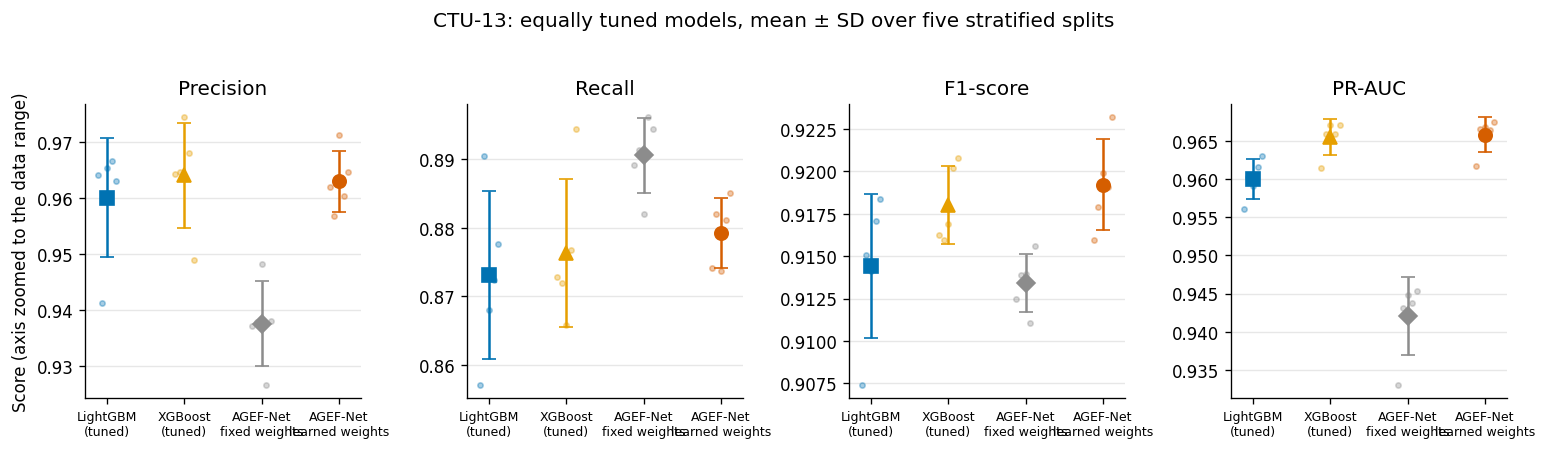

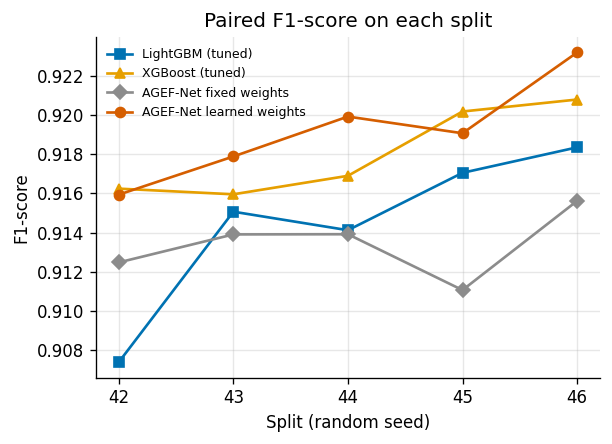

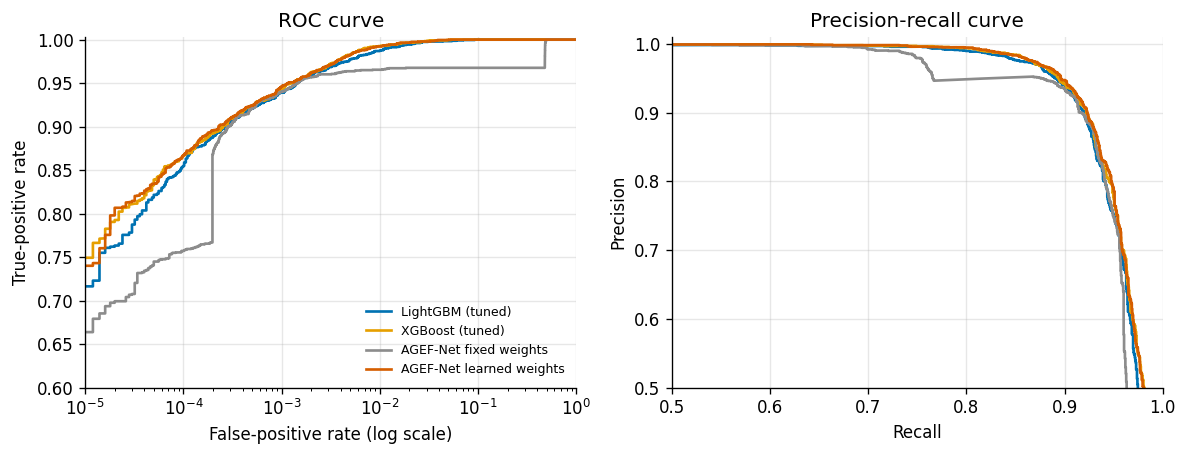

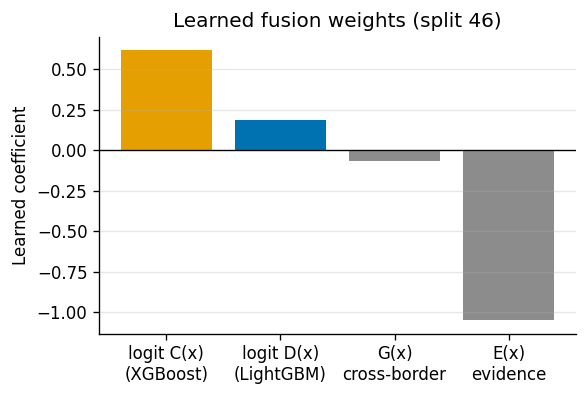

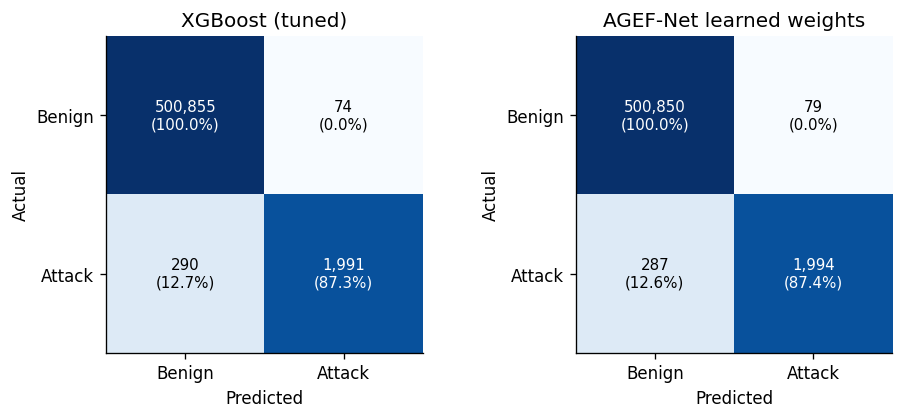

Saved: ['fig_A_metrics_five_splits.png', 'fig_B_paired_f1.png', 'fig_C_roc_pr_curves.png', 'fig_D_confusion_split42.png', 'fig_E_learned_weights.png']


In [ ]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix

# if the runtime was reset, Figures 1-2 still work from the saved CSV
if 'R' not in globals():
    R = pd.read_csv('/content/drive/MyDrive/agef_backup/table_v6_all_seeds.csv')
SYS = ['LightGBM alone (tuned)','XGBoost alone (tuned)',
       'AGEF-Net fixed weights (paper formula)','AGEF-Net learned weights (recommended)']
short = dict(zip(SYS, ['LightGBM\n(tuned)','XGBoost\n(tuned)','AGEF-Net\nfixed weights','AGEF-Net\nlearned weights']))
col   = dict(zip(SYS, ['#0072B2','#E69F00','#8c8c8c','#D55E00']))   # colour-blind safe
mark  = dict(zip(SYS, ['s','^','D','o']))                           # also readable in greyscale
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':120})
OUT='/content/figs'; os.makedirs(OUT,exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(f'{OUT}/{name}.png',dpi=300,bbox_inches='tight'); plt.show()

# ---------- Fig 1: mean ± SD over five splits (dots = individual splits) ----------
fig,axs=plt.subplots(1,4,figsize=(13,3.6))
for ax,m,t in zip(axs,['Precision','Recall','F1','PR_AUC'],['Precision','Recall','F1-score','PR-AUC']):
    for i,s in enumerate(SYS):
        v=R.loc[R.System==s,m].values
        ax.errorbar(i,v.mean(),yerr=v.std(ddof=1),fmt=mark[s],color=col[s],capsize=4,ms=8,zorder=3)
        ax.scatter(np.full(len(v),i)+np.linspace(-.12,.12,len(v)),v,s=10,color=col[s],alpha=.35,zorder=2)
    ax.set_xticks(range(4)); ax.set_xticklabels([short[s] for s in SYS],fontsize=7.5); ax.set_title(t)
    ax.grid(axis='y',alpha=.3)
axs[0].set_ylabel('Score (axis zoomed to the data range)')
fig.suptitle('CTU-13: equally tuned models, mean ± SD over five stratified splits',y=1.03)
save('fig_A_metrics_five_splits')

# ---------- Fig 2: paired F1 per split ----------
piv=R.pivot(index='seed',columns='System',values='F1')
plt.figure(figsize=(5.2,3.8))
for s in SYS: plt.plot(piv.index,piv[s],marker=mark[s],color=col[s],label=short[s].replace('\n',' '),lw=1.6)
plt.xticks(piv.index); plt.xlabel('Split (random seed)'); plt.ylabel('F1-score'); plt.grid(alpha=.3)
plt.legend(fontsize=7.5,frameon=False); plt.title('Paired F1-score on each split')
save('fig_B_paired_f1')

# ---------- Fig 3: ROC and PR curves (last split, seed 46, test set) ----------
if 'systems' in globals():
    yt=y[te]
    fig,axs=plt.subplots(1,2,figsize=(10,3.9))
    for s in SYS:
        sc=systems[s][1]
        fpr,tpr,_=roc_curve(yt,sc); p,r,_=precision_recall_curve(yt,sc)
        axs[0].plot(fpr,tpr,color=col[s],lw=1.6,label=short[s].replace('\n',' '))
        axs[1].plot(r,p,color=col[s],lw=1.6)
    axs[0].set_xscale('log'); axs[0].set_xlim(1e-5,1); axs[0].set_ylim(0.6,1.003)
    axs[0].set_xlabel('False-positive rate (log scale)'); axs[0].set_ylabel('True-positive rate'); axs[0].set_title('ROC curve')
    axs[1].set_xlim(0.5,1.0); axs[1].set_ylim(0.5,1.01); axs[1].set_xlabel('Recall'); axs[1].set_ylabel('Precision'); axs[1].set_title('Precision-recall curve')
    for a in axs: a.grid(alpha=.3)
    axs[0].legend(fontsize=7.5,frameon=False,loc='lower right')
    save('fig_C_roc_pr_curves')

    # ---------- Fig 5: learned fusion coefficients (last split, seed 46) ----------
    plt.figure(figsize=(5,3.4))
    names=['logit C(x)\n(XGBoost)','logit D(x)\n(LightGBM)','G(x)\ncross-border','E(x)\nevidence']
    w=st.coef_[0]; plt.bar(names,w,color=['#E69F00','#0072B2','#8c8c8c','#8c8c8c'])
    plt.axhline(0,color='k',lw=.8); plt.ylabel('Learned coefficient'); plt.title('Learned fusion weights (split 46)'); plt.grid(axis='y',alpha=.3)
    save('fig_E_learned_weights')

# ---------- Fig 4: confusion matrices, split 42 ----------
if 'keep42' in globals():
    fig,axs=plt.subplots(1,2,figsize=(8,3.6))
    for ax,s in zip(axs,[SYS[1],SYS[3]]):
        cm=confusion_matrix(y42,keep42[s]); pct=cm/cm.sum(1,keepdims=True)*100
        ax.imshow(pct,cmap='Blues',vmin=0,vmax=100)
        for i in range(2):
            for j in range(2): ax.text(j,i,f'{cm[i,j]:,}\n({pct[i,j]:.1f}%)',ha='center',va='center',color='white' if pct[i,j]>50 else 'black',fontsize=9)
        ax.set_xticks([0,1]); ax.set_xticklabels(['Benign','Attack']); ax.set_yticks([0,1]); ax.set_yticklabels(['Benign','Attack'])
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(short[s].replace('\n',' '))
    save('fig_D_confusion_split42')

import shutil; os.makedirs('/content/drive/MyDrive/agef_backup/figs',exist_ok=True)
for f in os.listdir(OUT): shutil.copy(f'{OUT}/{f}','/content/drive/MyDrive/agef_backup/figs/')
print('Saved:',sorted(os.listdir(OUT)))

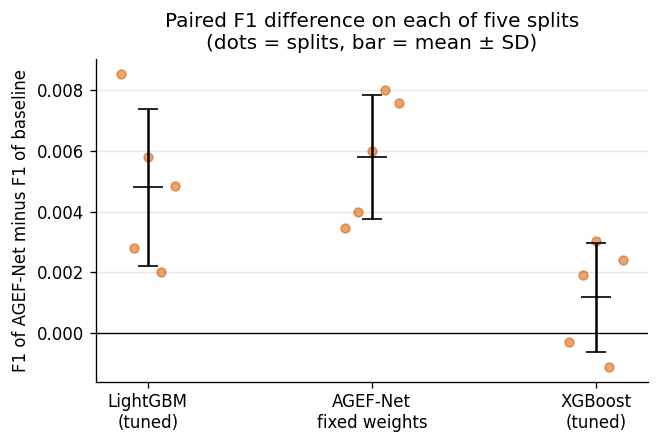

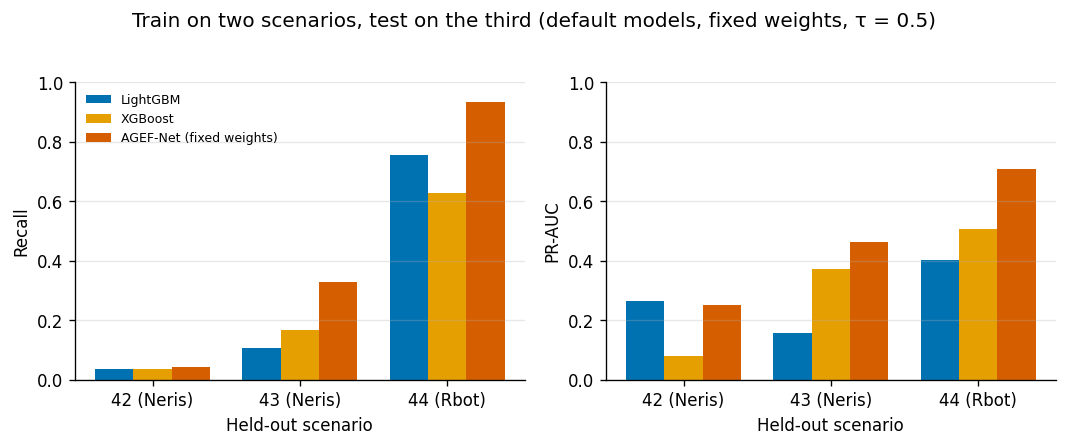

In [ ]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
OUT='/content/figs'; os.makedirs(OUT,exist_ok=True)
def save(n): plt.tight_layout(); plt.savefig(f'{OUT}/{n}.png',dpi=300,bbox_inches='tight'); plt.show()
if 'R' not in globals(): R=pd.read_csv('/content/drive/MyDrive/agef_backup/table_v6_all_seeds.csv')
SYS=['LightGBM alone (tuned)','XGBoost alone (tuned)','AGEF-Net fixed weights (paper formula)','AGEF-Net learned weights (recommended)']
ag=SYS[3]; piv=R.pivot(index='seed',columns='System',values='F1')

# Fig. 1: F1 gain of AGEF-Net (learned weights) over each baseline, per split
bases=[(SYS[0],'LightGBM\n(tuned)'),(SYS[2],'AGEF-Net\nfixed weights'),(SYS[1],'XGBoost\n(tuned)')]
plt.figure(figsize=(5.6,3.8))
for i,(b,n) in enumerate(bases):
    d=(piv[ag]-piv[b]).values
    plt.scatter(np.full(len(d),i)+np.linspace(-.12,.12,len(d)),d,color='#D55E00',alpha=.55,s=28,zorder=3)
    plt.errorbar(i,d.mean(),yerr=d.std(ddof=1),fmt='_',color='k',capsize=6,ms=18,zorder=4)
plt.axhline(0,color='k',lw=.8); plt.xticks(range(3),[n for _,n in bases])
plt.ylabel('F1 of AGEF-Net minus F1 of baseline'); plt.grid(axis='y',alpha=.3)
plt.title('Paired F1 difference on each of five splits\n(dots = splits, bar = mean ± SD)'); save('fig_paired_f1_gain')

# Fig. 2: held-out-scenario evaluation (values from Table 14 of the manuscript)
sc=['42 (Neris)','43 (Neris)','44 (Rbot)']
rec={'LightGBM':[.0374,.1069,.7554],'XGBoost':[.0349,.1671,.6286],'AGEF-Net (fixed weights)':[.0433,.3288,.9328]}
pra={'LightGBM':[.2643,.1559,.4016],'XGBoost':[.0791,.3727,.5049],'AGEF-Net (fixed weights)':[.2513,.4618,.7092]}
cl={'LightGBM':'#0072B2','XGBoost':'#E69F00','AGEF-Net (fixed weights)':'#D55E00'}
fig,axs=plt.subplots(1,2,figsize=(9,3.6)); x=np.arange(3); w=.26
for ax,dct,t in [(axs[0],rec,'Recall'),(axs[1],pra,'PR-AUC')]:
    for k,(n,v) in enumerate(dct.items()): ax.bar(x+(k-1)*w,v,w,label=n,color=cl[n])
    ax.set_xticks(x); ax.set_xticklabels(sc); ax.set_xlabel('Held-out scenario'); ax.set_ylabel(t); ax.set_ylim(0,1); ax.grid(axis='y',alpha=.3)
axs[0].legend(fontsize=7.5,frameon=False,loc='upper left'); fig.suptitle('Train on two scenarios, test on the third (default models, fixed weights, \u03c4 = 0.5)',y=1.02)
save('fig_heldout_scenarios')